In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

%matplotlib inline

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path.cwd().parent

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: d:\spamEmail\unsaturated\outputs


In [3]:
X_reduced = np.load(OUTPUT_DIR / "X_reduced.npy")

y_true = np.load(OUTPUT_DIR / "y_true.npy")

source = np.load(
    OUTPUT_DIR / "source.npy",
    allow_pickle=True
)

print("Feature matrix shape:", X_reduced.shape)
print("Labels shape:", y_true.shape)
print("Sources shape:", source.shape)

Feature matrix shape: (108671, 100)
Labels shape: (108671,)
Sources shape: (108671,)


In [4]:
from sklearn.model_selection import train_test_split

sample_indices = np.random.default_rng(
    RANDOM_STATE
).choice(
    len(X_reduced),
    size=10000,
    replace=False
)

X_sample = X_reduced[sample_indices]
y_sample = y_true[sample_indices]

print("Sample shape:", X_sample.shape)

Sample shape: (10000, 100)


In [5]:
dbscan = DBSCAN(
    eps=1.0,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

dbscan_labels = dbscan.fit_predict(X_sample)

print("DBSCAN completed!")

DBSCAN completed!


In [6]:
dbscan_counts = pd.Series(
    dbscan_labels
).value_counts().sort_index()

print("Cluster distribution:")
print(dbscan_counts)

print("\nNumber of clusters excluding noise:")
print(len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("\nNumber of noise points:")
print(np.sum(dbscan_labels == -1))

Cluster distribution:
-1     1534
 0     2602
 1     1026
 2      612
 3       11
 4      314
 5      465
 6      197
 7     1553
 8      184
 9       77
 10      26
 11      31
 12      26
 13      39
 14      70
 15      84
 16      16
 17      30
 18     120
 19      54
 20     140
 21      41
 22      37
 23      50
 24      24
 25     128
 26      28
 27      40
 28      14
 29      17
 30      33
 31      16
 32      17
 33      14
 34      14
 35      16
 36      17
 37      15
 38      11
 39      13
 40      20
 41      15
 42      12
 43      15
 44      33
 45      10
 46      15
 47      10
 48      17
 49      12
 50      10
 51      12
 52      10
 53      17
 54      15
 55      11
 56      10
Name: count, dtype: int64

Number of clusters excluding noise:
57

Number of noise points:
1534


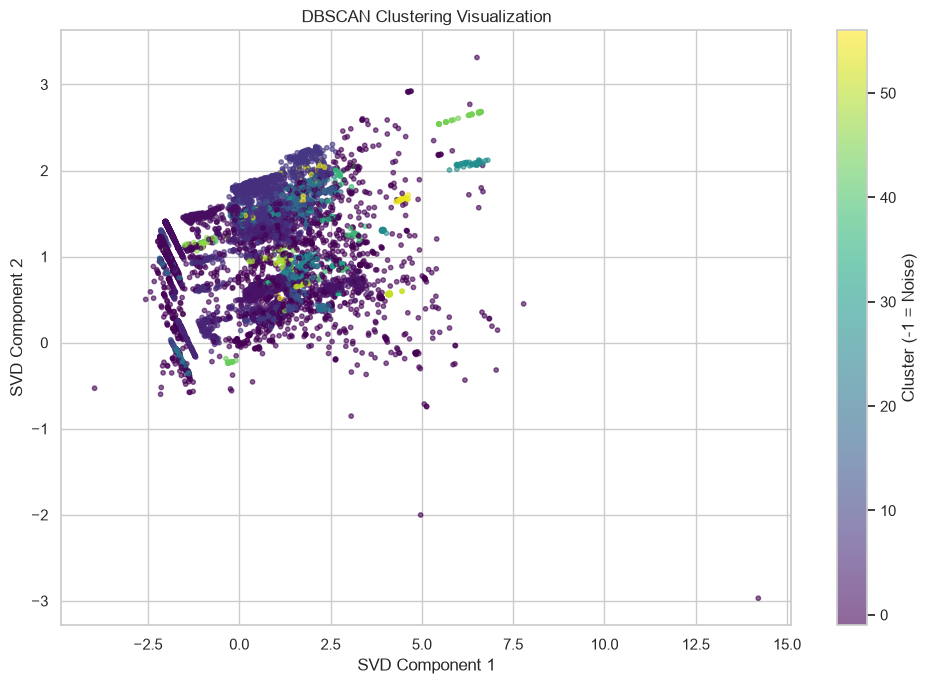

In [7]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("DBSCAN Clustering Visualization")

plt.colorbar(scatter, label="Cluster (-1 = Noise)")

plt.tight_layout()
plt.show()

In [8]:
dbscan_ari = adjusted_rand_score(
    y_sample,
    dbscan_labels
)

dbscan_nmi = normalized_mutual_info_score(
    y_sample,
    dbscan_labels
)

print("DBSCAN ARI:", round(dbscan_ari, 4))
print("DBSCAN NMI:", round(dbscan_nmi, 4))

DBSCAN ARI: 0.1295
DBSCAN NMI: 0.1936


In [9]:
non_noise_mask = dbscan_labels != -1

non_noise_labels = dbscan_labels[non_noise_mask]

unique_clusters = np.unique(non_noise_labels)

if (
    len(unique_clusters) >= 2
    and len(unique_clusters) < len(non_noise_labels)
):
    dbscan_silhouette = silhouette_score(
        X_sample[non_noise_mask],
        non_noise_labels,
        sample_size=min(2000, len(non_noise_labels)),
        random_state=RANDOM_STATE
    )

    print(
        "DBSCAN Silhouette Score:",
        round(dbscan_silhouette, 4)
    )
else:
    dbscan_silhouette = np.nan

    print(
        "Silhouette score cannot be calculated "
        "because DBSCAN did not produce suitable clusters."
    )

DBSCAN Silhouette Score: 0.1721


In [10]:
dbscan_comparison = pd.crosstab(
    pd.Series(y_sample, name="Actual Label"),
    pd.Series(dbscan_labels, name="DBSCAN Cluster")
)

dbscan_comparison

DBSCAN Cluster,-1,0,1,2,3,4,5,6,7,8,...,47,48,49,50,51,52,53,54,55,56
Actual Label,,,,,,,,,,,,,,,,,,,,,
0.0,657,2514,501,13,0,4,46,4,972,97,...,0,0,0,0,12,6,17,0,11,10
1.0,877,88,525,599,11,310,419,193,581,87,...,10,17,12,10,0,4,0,15,0,0


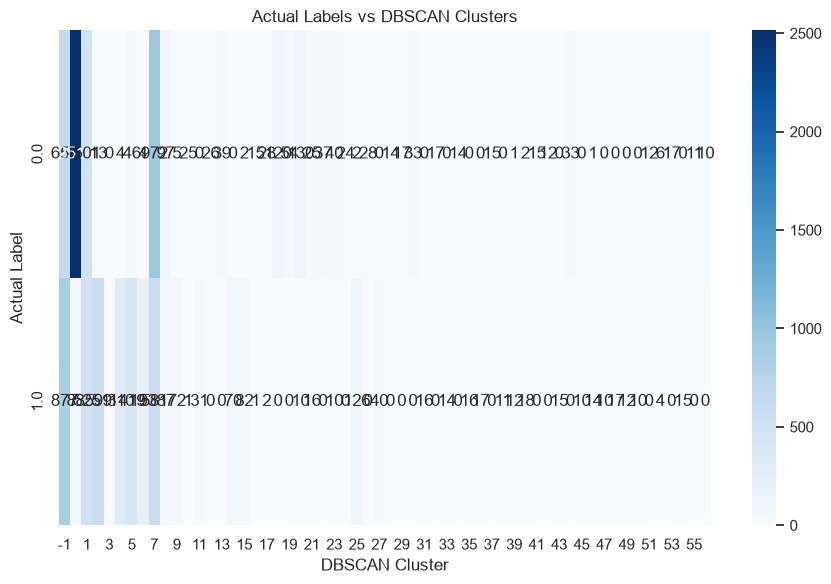

In [11]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    dbscan_comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Labels vs DBSCAN Clusters")
plt.tight_layout()
plt.show()

In [12]:
np.save(
    OUTPUT_DIR / "dbscan_sample_indices.npy",
    sample_indices
)

np.save(
    OUTPUT_DIR / "dbscan_labels.npy",
    dbscan_labels
)

dbscan_comparison.to_csv(
    OUTPUT_DIR / "dbscan_label_comparison.csv"
)

dbscan_metrics = pd.DataFrame([{
    "Algorithm": "DBSCAN",
    "Sample Size": len(X_sample),
    "Number of Clusters": len(unique_clusters),
    "Noise Points": int(np.sum(dbscan_labels == -1)),
    "ARI": dbscan_ari,
    "NMI": dbscan_nmi,
    "Silhouette": dbscan_silhouette
}])

dbscan_metrics.to_csv(
    OUTPUT_DIR / "dbscan_metrics.csv",
    index=False
)

print("DBSCAN results saved!")

DBSCAN results saved!


In [13]:
from sklearn.ensemble import IsolationForest

In [14]:
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Isolation Forest model created!")

Isolation Forest model created!


In [15]:
isolation_predictions = isolation_forest.fit_predict(
    X_reduced
)

print("Isolation Forest completed!")

Isolation Forest completed!


In [16]:
isolation_labels = np.where(
    isolation_predictions == -1,
    1,
    0
)

print("Anomaly distribution:")

print(
    pd.Series(isolation_labels).value_counts()
)

Anomaly distribution:
0    107955
1       716
Name: count, dtype: int64


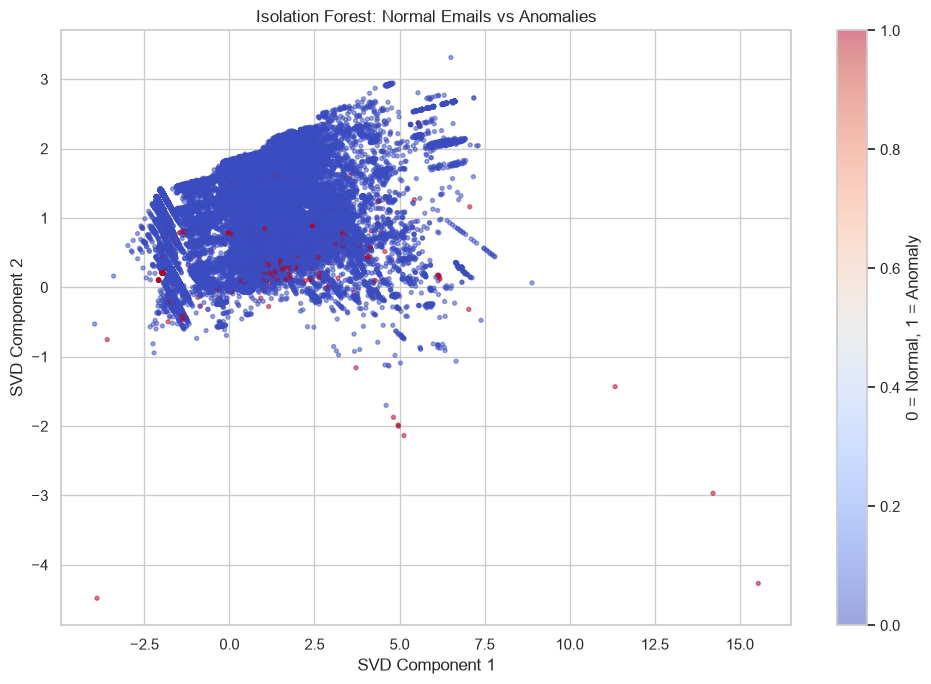

In [17]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=isolation_labels,
    cmap="coolwarm",
    s=8,
    alpha=0.5
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Isolation Forest: Normal Emails vs Anomalies")

plt.colorbar(scatter, label="0 = Normal, 1 = Anomaly")

plt.tight_layout()
plt.show()

In [18]:
isolation_ari = adjusted_rand_score(
    y_true,
    isolation_labels
)

isolation_nmi = normalized_mutual_info_score(
    y_true,
    isolation_labels
)

print("Isolation Forest ARI:", round(isolation_ari, 4))
print("Isolation Forest NMI:", round(isolation_nmi, 4))

Isolation Forest ARI: 0.0009
Isolation Forest NMI: 0.0007


In [19]:
isolation_comparison = pd.crosstab(
    pd.Series(y_true, name="Actual Label"),
    pd.Series(isolation_labels, name="Predicted Anomaly")
)

isolation_comparison

Predicted Anomaly,0,1
Actual Label,,
0.0,60336,301
1.0,47619,415


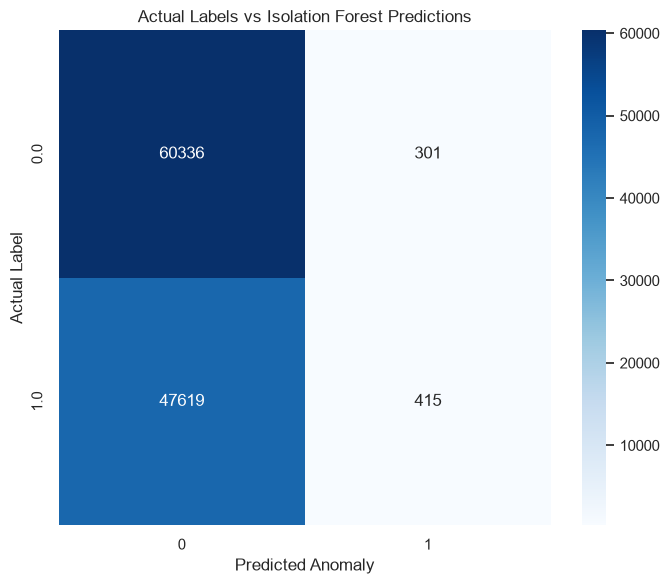

In [20]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    isolation_comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Labels vs Isolation Forest Predictions")
plt.tight_layout()
plt.show()

In [21]:
np.save(
    OUTPUT_DIR / "isolation_forest_labels.npy",
    isolation_labels
)

joblib.dump(
    isolation_forest,
    OUTPUT_DIR / "isolation_forest_model.joblib"
)

isolation_comparison.to_csv(
    OUTPUT_DIR / "isolation_forest_comparison.csv"
)

isolation_metrics = pd.DataFrame([{
    "Algorithm": "Isolation Forest",
    "Total Emails": len(X_reduced),
    "Normal Emails": int(np.sum(isolation_labels == 0)),
    "Anomalies": int(np.sum(isolation_labels == 1)),
    "ARI": isolation_ari,
    "NMI": isolation_nmi
}])

isolation_metrics.to_csv(
    OUTPUT_DIR / "isolation_forest_metrics.csv",
    index=False
)

print("Isolation Forest results saved!")

Isolation Forest results saved!


In [22]:
print("OTHER ALGORITHMS SUMMARY")
print("------------------------")

print("\nDBSCAN")
print("Sample size:", len(X_sample))
print("Clusters:", len(unique_clusters))
print("Noise points:", np.sum(dbscan_labels == -1))
print("ARI:", round(dbscan_ari, 4))
print("NMI:", round(dbscan_nmi, 4))
print("Silhouette:", dbscan_silhouette)

print("\nISOLATION FOREST")
print("Total emails:", len(X_reduced))
print("Anomalies:", np.sum(isolation_labels == 1))
print("ARI:", round(isolation_ari, 4))
print("NMI:", round(isolation_nmi, 4))

OTHER ALGORITHMS SUMMARY
------------------------

DBSCAN
Sample size: 10000
Clusters: 57
Noise points: 1534
ARI: 0.1295
NMI: 0.1936
Silhouette: 0.1720803986988698

ISOLATION FOREST
Total emails: 108671
Anomalies: 716
ARI: 0.0009
NMI: 0.0007
